In [3]:
import pandas as pd
import numpy as np
import ast
import re

# Load TED Talks dataset
df = pd.read_csv('/content/ted_talks_final_cleaned.csv')

# Check dataset
print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset loaded successfully!
Shape: (63, 32)
Columns: ['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript', 'duration_minutes', 'log_views', 'log_comments', 'recorded_year', 'published_year', 'topic_count', 'title_word_count', 'description_word_count', 'transcript_word_count', 'about_speaker_word_count', 'publication_year', 'related_talk_count', 'combined_text']


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,...,recorded_year,published_year,topic_count,title_word_count,description_word_count,transcript_word_count,about_speaker_word_count,publication_year,related_talk_count,combined_text
0,1,averting the climate crisis,al gore,Al Gore,climate advocate,nobel laureate al gore focused the world’s att...,3523392,2006-02-25,2006-06-27,TED2006,...,2006.0,2006,12,4,38,2148,23,2006,0,averting the climate crisis alternative energy...
1,92,the best stats youve ever seen,hans rosling,Hans Rosling,global health expert data visionary,in hans rosling’s hands data sings global tren...,14501685,2006-02-22,2006-06-27,TED2006,...,2006.0,2006,13,6,26,3140,32,2006,0,the best stats youve ever seen Africa Asia Goo...
2,7,simplicity sells,david pogue,David Pogue,technology columnist,david pogue is the personal technology columni...,1920832,2006-02-24,2006-06-27,TED2006,...,2006.0,2006,10,2,31,3345,43,2006,0,simplicity sells computers entertainment inter...
3,53,greening the ghetto,majora carter,Majora Carter,activist for environmental justice,majora carter redefined the field of environme...,2664069,2006-02-26,2006-06-27,TED2006,...,2006.0,2006,10,3,30,3052,31,2006,0,greening the ghetto MacArthur grant activism b...
4,66,do schools kill creativity,sir ken robinson,Sir Ken Robinson,author educator,creativity expert sir ken robinson challenges ...,65051954,2006-02-25,2006-06-27,TED2006,...,2006.0,2006,7,4,21,3158,30,2006,0,do schools kill creativity children creativity...


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(stop_words='english')

# Generate TF-IDF matrix using the 'combined_text' column
tfidf_matrix = tfidf.fit_transform(df['combined_text'])

print("TF-IDF matrix created successfully!")
print("Matrix Shape:", tfidf_matrix.shape)

TF-IDF matrix created successfully!
Matrix Shape: (63, 12608)


TED TALKS RECOMMENDATION MODEL EVALUATION


,Metric,At K=5,At K=10
0,Precision,0.9206,0.8651
1,Recall,0.1041,0.1922
2,NDCG,0.9308,0.8891
3,MAP,0.8939,0.8225


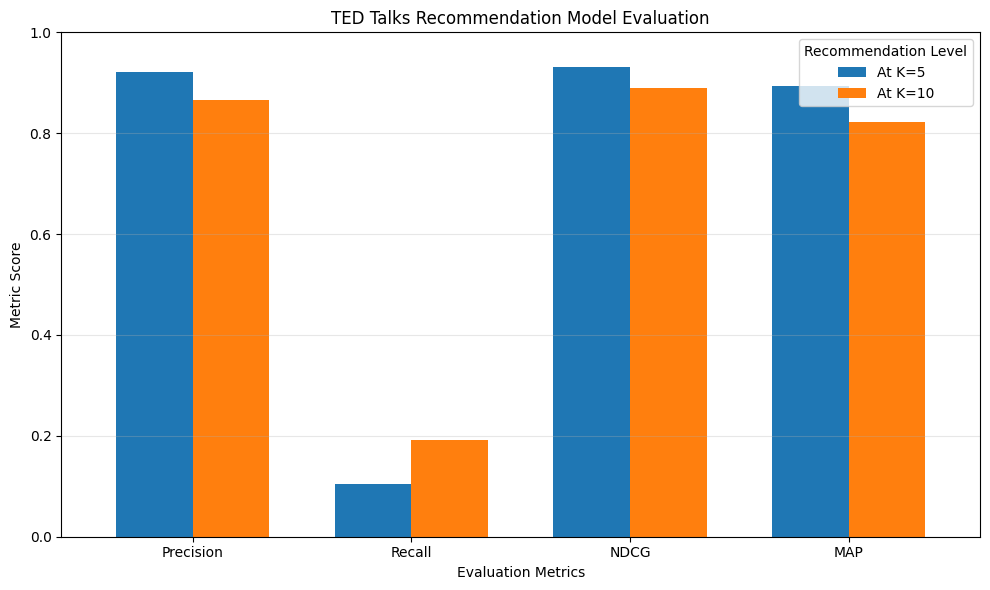

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ast
from sklearn.metrics.pairwise import cosine_similarity

# 1. Prepare topic sets - split by spaces to extract individual topics correctly
def topic_set(value):
    try:
        parsed = ast.literal_eval(str(value))
        if isinstance(parsed, (list, tuple, set)):
            raw_items = [str(x).strip().lower() for x in parsed]
        else:
            raw_items = [str(parsed).strip().lower()]
    except:
        raw_items = [str(value).strip().lower()]

    # Split each multi-word topic string into individual topic words
    individual_topics = set()
    for item in raw_items:
        for word in item.replace(",", " ").split():
            if word.strip():
                individual_topics.add(word.strip())
    return individual_topics

topic_sets = df["topics"].apply(topic_set).tolist()

# 2. Identify relevant talks
def get_relevant_talks(index):
    return {
        i for i, topics in enumerate(topic_sets)
        if i != index and topic_sets[index].intersection(topics)
    }

# 3. Generate recommendations
def get_top_recommendations(index, k):
    scores = cosine_similarity(
        tfidf_matrix[index], tfidf_matrix
    ).flatten()

    scores[index] = -1
    return np.argsort(scores)[::-1][:k].tolist()

# 4. Evaluation metrics
def precision_at_k(recommendations, relevant, k):
    return sum(x in relevant for x in recommendations[:k]) / k

def recall_at_k(recommendations, relevant, k):
    if not relevant:
        return 0
    return sum(x in relevant for x in recommendations[:k]) / len(relevant)

def dcg_at_k(recommendations, relevant, k):
    return sum(
        (1 if item in relevant else 0) / np.log2(rank + 1)
        for rank, item in enumerate(recommendations[:k], start=1)
    )

def ndcg_at_k(recommendations, relevant, k):
    actual = dcg_at_k(recommendations, relevant, k)
    ideal = dcg_at_k(list(relevant)[:k], relevant, k)
    return actual / ideal if ideal else 0

def average_precision_at_k(recommendations, relevant, k):
    if not relevant:
        return 0

    hits = 0
    total = 0

    for rank, item in enumerate(recommendations[:k], start=1):
        if item in relevant:
            hits += 1
            total += hits / rank

    return total / min(len(relevant), k)

# 5. Evaluate model
def evaluate_model(k):
    rows = []

    for index in range(len(df)):
        relevant = get_relevant_talks(index)

        if not relevant:
            continue

        recommendations = get_top_recommendations(index, k)

        rows.append({
            "Precision": precision_at_k(recommendations, relevant, k),
            "Recall": recall_at_k(recommendations, relevant, k),
            "NDCG": ndcg_at_k(recommendations, relevant, k),
            "MAP": average_precision_at_k(recommendations, relevant, k)
        })

    return pd.DataFrame(rows)

results_5 = evaluate_model(5)
results_10 = evaluate_model(10)

# STEP 6: Create metrics table
metric_names = ["Precision", "Recall", "NDCG", "MAP"]

metrics_table = pd.DataFrame({
    "Metric": metric_names,
    "At K=5": [
        results_5["Precision"].mean(),
        results_5["Recall"].mean(),
        results_5["NDCG"].mean(),
        results_5["MAP"].mean()
    ],
    "At K=10": [
        results_10["Precision"].mean(),
        results_10["Recall"].mean(),
        results_10["NDCG"].mean(),
        results_10["MAP"].mean()
    ]
})

print("TED TALKS RECOMMENDATION MODEL EVALUATION")
display(metrics_table.round(4))

# STEP 7: Visualize results
ax = metrics_table.set_index("Metric").plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    width=0.7
)

plt.title("TED Talks Recommendation Model Evaluation")
plt.ylabel("Metric Score")
plt.xlabel("Evaluation Metrics")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Recommendation Level")
plt.tight_layout()
plt.show()